# Individual Student Submission

**Student:** WANG HE  
**Student ID:** MC660942  
**Course:** CISC7204 Data Science and Data Visualization  
**Coursework:** Assignment 2 — Individual Module Work


## Teacher-specified data provenance

This notebook uses the datasets named in the original teacher-provided notebook. The files were downloaded unchanged from the IBM Skills Network URLs shown in the original instructions. A URL, byte-size, and SHA-256 manifest is included with the submission package as `teacher_dataset_manifest.json`.


<center>
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="cognitiveclass.ai logo">
</center>


# Basic Plotly Charts

Estimated time needed: 45 minutes


# Objectives


After completing this lab, you will be able to:

*   Use plotly graph objects and plotly express libraries to plot different types of charts
*   Create interesting visualizations on Airline Reporting Carrier On-Time Performance Dataset 







# Plotly graph objects and Plotly express libraries to plot different types of charts 

## Plotly Libraries

**plotly.graph_objects:** 
This is a low level interface to figures, traces and layout. The Plotly graph objects module provides an automatically generated hierarchy of classes ( figures, traces, and layout) called graph objects. These graph objects represent figures with a top-level class plotly.graph_objects.Figure.

**plotly.express:** 
Plotly express is a high-level wrapper for Plotly. It is a recommended starting point for creating the most common figures provided by Plotly using a simpler syntax. It uses graph objects internally.
Now let us use these libraries to plot some charts
We will start with plotly_graph_objects to plot line and scatter plots
> Note: You can hover the mouse over the charts whenever you want to view any statistics in the visualization charts 




## Exercise I: Get Started with Different Chart types in Plotly



  

 
 
 

 
 




In [1]:
# Import required libraries
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

## 1. Scatter Plot: 
A scatter plot shows the relationship between 2 variables on the x and y-axis. The data points here appear scattered when plotted on a two-dimensional plane. Using scatter plots, we can create exciting visualizations to express various relationships, such as:

* Height vs weight of persons
* Engine size vs automobile price
* Exercise time vs Body Fat


In [2]:
# Replace illustrative invented numbers with observations from the course download.
from pathlib import Path
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/airline_data.csv'
files = [p / '可选_复现数据' / 'Teacher_Datasets' / 'airline_data.csv' for p in Path.cwd().parents]
source = next((p for p in files if p.exists()), url)
observed_flights = pd.read_csv(source, encoding='ISO-8859-1', low_memory=False)
example_flights = observed_flights.dropna(subset=['Distance', 'AirTime']).head(60)
distance_array = example_flights['Distance'].to_numpy()
airtime_array = example_flights['AirTime'].to_numpy()
assert len(distance_array) == len(airtime_array) == 60
print('Source:', url)
example_flights[['Year', 'Month', 'Distance', 'AirTime']].head()

Source: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/airline_data.csv


,Year,Month,Distance,AirTime
0,1998,4,224.0,37.0
1,2013,5,277.0,54.0
4,2017,8,692.0,102.0
5,2014,4,1171.0,175.0
6,2011,8,1011.0,128.0


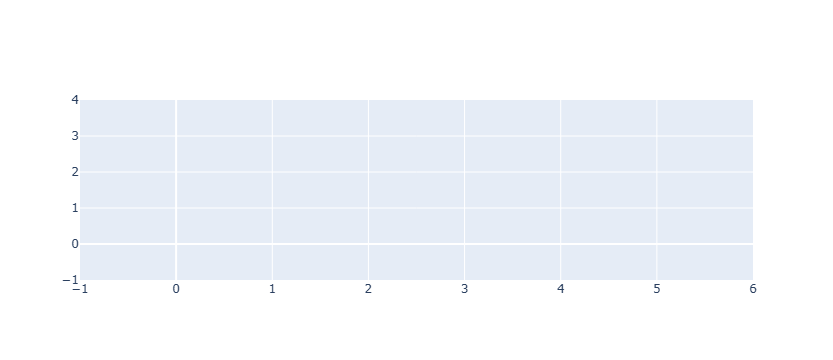

In [3]:
##First we will create an empty figure using go.Figure()
fig=go.Figure()
fig

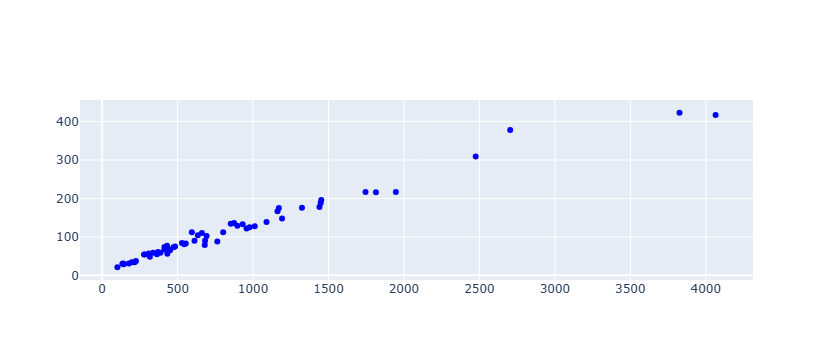

In [4]:
#Next we will create a scatter plot by using the add_trace function and use the go.scatter() function within it
# In go.Scatter we define the x-axis data,y-axis data and define the mode as markers with color of the marker as blue
fig.add_trace(go.Scatter(x=distance_array, y=airtime_array, mode='markers', marker=dict(color='blue')))

**However in the previous output title, x-axis and y-axis labels are missing. Let us use the update_layout function to update the title and labels.**


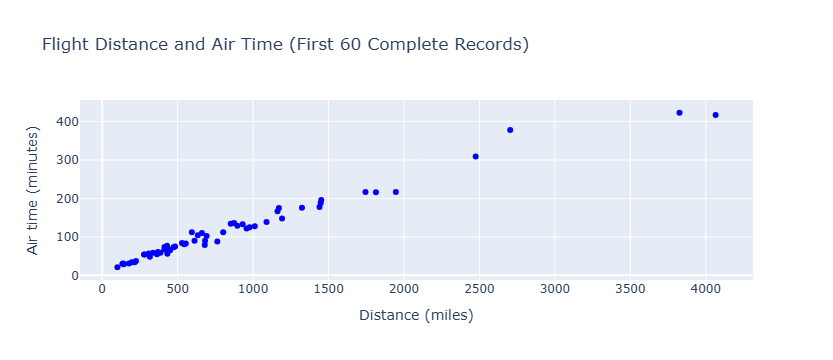

In [5]:
## Here we update these values under function attributes such as title,xaxis_title and yaxis_title
fig.update_layout(title='Flight Distance and Air Time (First 60 Complete Records)', xaxis_title='Distance (miles)', yaxis_title='Air time (minutes)')
# Display the figure
fig.show()

#### Interpretation

The points are the first 60 complete distance/air-time pairs in the downloaded course flight file. Distance is in miles and air time in minutes. This selected subset demonstrates chart construction and is not representative of all flights.

## 2. Line Plot: 
A line plot shows information that changes continuously with time. Here the data points are connected by straight lines. Line plots are also plotted on a two dimensional plane like scatter plots. Using line plots, we can create exciting visualizations to illustrate:

  * Annual revenue growth
  * Stock Market analysis over time
  * Product Sales over time


In [6]:
# Monthly flight counts are calculated from the downloaded records.
monthly_flights = observed_flights.groupby('Month')['Flights'].sum().sort_index()
months_array = monthly_flights.index
numberofflights_array = monthly_flights.to_numpy()

In [7]:
##First we will create an empty figure using go.Figure()
fig=go.Figure()

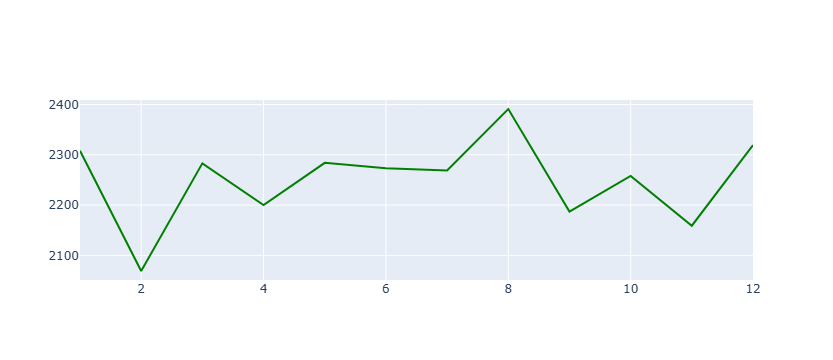

In [8]:
#Next we will create a line plot by using the add_trace function and use the go.scatter() function within it
# In go.Scatter we define the x-axis data,y-axis data and define the mode as lines with color of the marker as green
fig.add_trace(go.Scatter(x=months_array, y=numberofflights_array, mode='lines', marker=dict(color='green')))

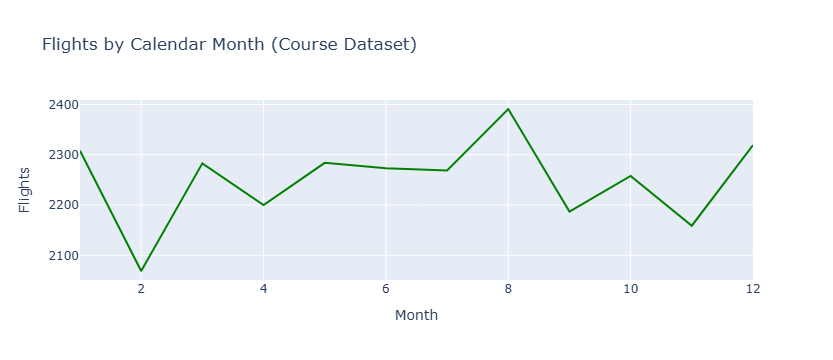

In [9]:


## Here we update these values under function attributes such as title,xaxis_title and yaxis_title
fig.update_layout(title='Flights by Calendar Month (Course Dataset)', xaxis_title='Month', yaxis_title='Flights')
# Display the figure
fig.show()

#### Interpretation

The line aggregates flight records by calendar month across all years in the supplied file. It is a monthly distribution of this extract, not bicycle sales or one specific year.

We will now use plotly express library to plot the other graphs


  
## 3.Bar Plot: 
A bar plot represents categorical data in rectangular bars. Each category is defined on one axis, and the value counts for this category are represented on another axis. Bar charts are generally used to compare values.We can use bar plots in visualizing:

 * Pizza delivery time in peak and non peak hours
 * Population comparison by gender
 * Number of views by movie name


In [10]:
# State counts are calculated rather than invented class pass percentages.
state_flights = observed_flights.groupby('DestState')['Flights'].sum().nlargest(5)
score_array = state_flights.to_numpy()
grade_array = state_flights.index

**Plotly Express constructs a bar chart directly from the destination labels and flight totals calculated above.**

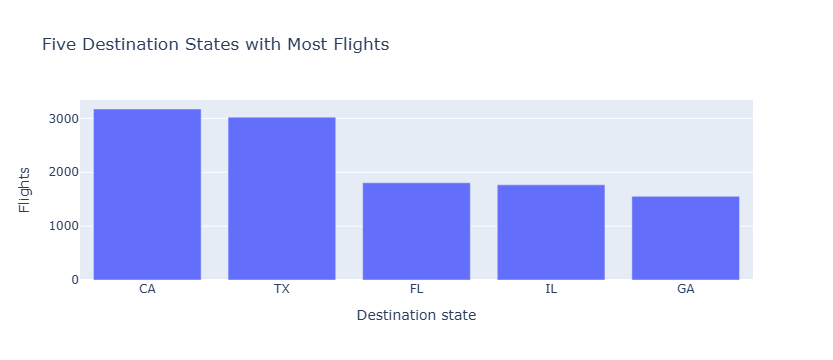

In [11]:
fig = px.bar(x=grade_array, y=score_array, title='Five Destination States with Most Flights')
fig.update_layout(xaxis_title='Destination state', yaxis_title='Flights')
fig.show()

#### Interpretation

The five bars are the largest destination-state flight totals in the downloaded course extract. They are counts in this extract, not population-adjusted rates.


## 4.Histogram: 
 A histogram is used to represent continuous data in the form of bar. Each bar has discrete values in bar graphs, whereas in histograms, we have bars representing a range of values. Histograms show frequency distributions. We can use histograms to visualize:
 
 * Students marks distribution
 * Frequency of waiting time of customers in a Bank


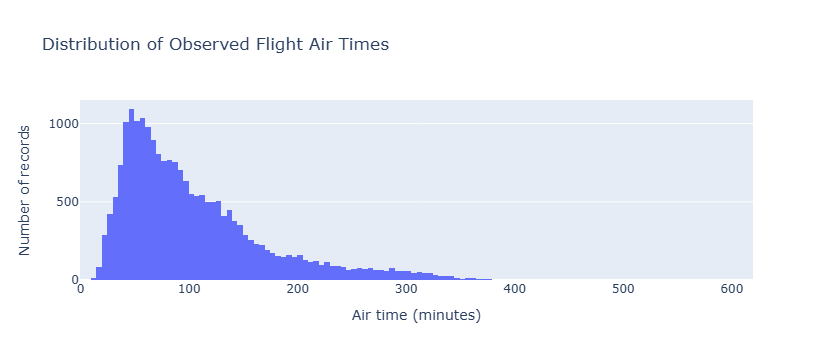

In [12]:
# Histogram of observed air times; missing values are excluded, not invented.
fig = px.histogram(observed_flights.dropna(subset=['AirTime']), x='AirTime',
                   title='Distribution of Observed Flight Air Times')
fig.update_layout(xaxis_title='Air time (minutes)', yaxis_title='Number of records')
fig.show()

#### Interpretation

The histogram shows the frequency distribution of nonmissing air-time observations. Its bars count records in the supplied extract.

## 5. Bubble Plot: 
A bubble plot is used to show the relationship between 3 or more variables. It is an extension of a scatter plot. Bubble plots are ideal for visualizing:

  * Global Economic position of Industries
  * Impact of viruses on Diseases


In [13]:
# Flight counts, not invented crime statistics.
df = observed_flights[['DestState', 'Flights']].dropna().copy()
df.head()

,DestState,Flights
0,WA,1.0
1,VA,1.0
2,IL,1.0
3,AZ,1.0
4,CO,1.0


In [14]:
bub_data = df.groupby('DestState')['Flights'].sum().nlargest(5).reset_index()

In [15]:
##Display the grouped dataframe
bub_data

,DestState,Flights
0,CA,3174.0
1,TX,3023.0
2,FL,1804.0
3,IL,1766.0
4,GA,1553.0


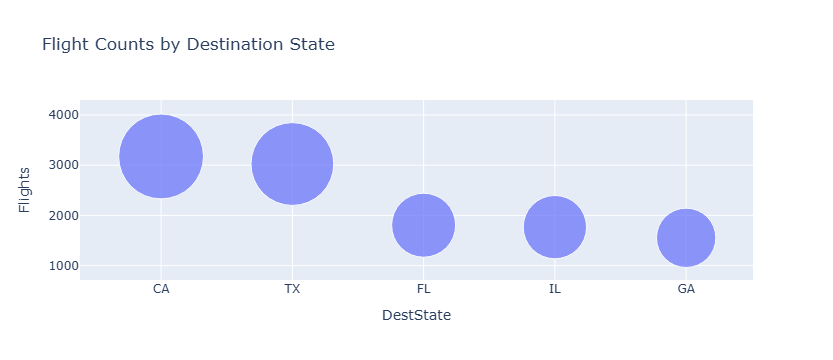

In [16]:
fig = px.scatter(bub_data, x='DestState', y='Flights', size='Flights',
                 hover_name='DestState', title='Flight Counts by Destination State', size_max=60)
fig.show()

#### Interpretation

Bubble area encodes the flight count for each of the five leading destination states in this extract. These are counts rather than crime rates.

 ## 6.Pie Plot: 
 A pie plot is a circle chart mainly used to represent proportion of part of given data with respect to the whole data. Each slice represents a proportion and on total of the proportion becomes a whole. We can use bar plots in visualizing:
 
 * Sales turnover percentatge with respect to different products
 * Monthly expenditure of a Family


In [17]:
# Pie-sector totals come from observed flights.
distance_totals = observed_flights.groupby('DistanceGroup')['Flights'].sum()
exp_percent = distance_totals.to_numpy()
house_holdcategories = distance_totals.index

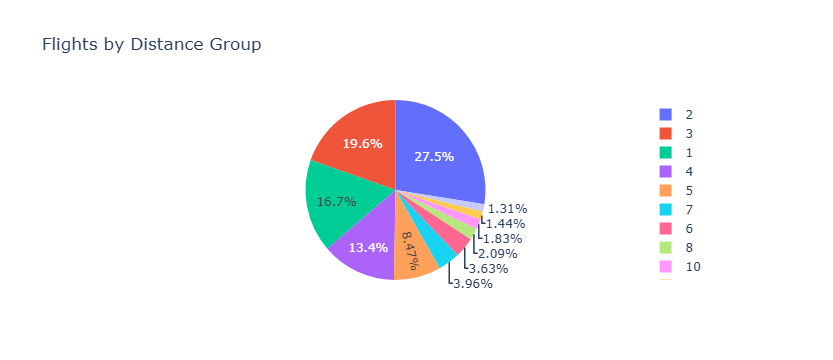

In [18]:
fig = px.pie(values=exp_percent, names=house_holdcategories, title='Flights by Distance Group')
fig.show()

#### Interpretation

Each sector shows the share of flights in a distance group within this downloaded dataset.

## 7.Sunburst Charts: 
Sunburst charts represent hierarchial data in the form of concentric circles. Here the innermost circle is the root node which defines the parent, and then the outer rings move down the hierarchy from the centre. They are also called radial charts.We can use them to plot

* Worldwide mobile Sales where we can drill down as follows:   
    * innermost circle represents total sales  
    * first outer circle represents continentwise sales
    * second outer circle represents countrywise sales within each continent
    
    
* Disease outbreak hierarchy


* Real Estate Industrial chain
     


Excluded incomplete hierarchy records: 7


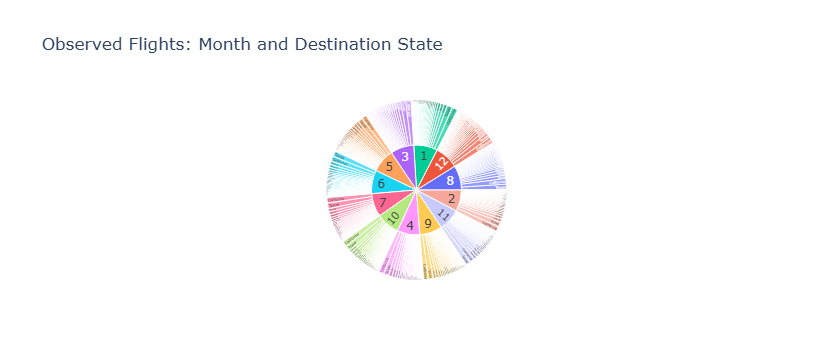

In [19]:
# Exclude source records without a complete hierarchy; do not invent states.
hierarchy = observed_flights.dropna(subset=['Month', 'DestStateName', 'Flights'])
print('Excluded incomplete hierarchy records:', len(observed_flights) - len(hierarchy))
hierarchy = hierarchy.groupby(['Month', 'DestStateName'], as_index=False)['Flights'].sum()
fig = px.sunburst(hierarchy, path=['Month', 'DestStateName'], values='Flights',
                  title='Observed Flights: Month and Destination State')
fig.show()

#### Interpretation

The inner ring groups flights by calendar month; the outer ring splits each month by destination state. Sector values sum the Flights column.

## II- Practice Exercises: Apply your Plotly Skills to an Airline Dataset

The Reporting Carrier On-Time Performance Dataset contains information on approximately 200 million domestic US flights reported to the United States Bureau of Transportation Statistics. The dataset contains basic information about each flight (such as date, time, departure airport, arrival airport) and, if applicable, the amount of time the flight was delayed and information about the reason for the delay. This dataset can be used to predict the likelihood of a flight arriving on time.

Preview data, dataset metadata, and data glossary [here.](https://dax-cdn.cdn.appdomain.cloud/dax-airline/1.0.1/data-preview/index.html)


# Read Data


In [20]:
from pathlib import Path
official_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/airline_data.csv'
candidates = [Path('airline_data.csv'), Path('Teacher_Datasets/airline_data.csv'), Path('../Teacher_Datasets/airline_data.csv')]
candidates += [parent / '可选_复现数据' / 'Teacher_Datasets' / 'airline_data.csv' for parent in Path.cwd().parents]
data_source = next((path for path in candidates if path.exists()), official_url)
airline_data = pd.read_csv(data_source, encoding='ISO-8859-1', dtype={'Div1Airport': str, 'Div1TailNum': str, 'Div2Airport': str, 'Div2TailNum': str})
print(f'Teacher-specified data source: {data_source}')

Teacher-specified data source: C:\Users\Admin\Documents\Codex\2026-10-25\new-chat\work\wang_he\candidate\MC660942_WANG_HE\可选_复现数据\Teacher_Datasets\airline_data.csv


In [21]:
# Preview the first 5 lines of the loaded data 
airline_data.head()

,Unnamed: 0,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,...,Div4WheelsOff,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum
0,1295781,1998,2,4,2,4,1998-04-02,AS,19930,AS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1125375,2013,2,5,13,1,2013-05-13,EV,20366,EV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,118824,1993,3,9,25,6,1993-09-25,UA,19977,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,634825,1994,4,11,12,6,1994-11-12,HP,19991,HP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1888125,2017,3,8,17,4,2017-08-17,UA,19977,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
airline_data

,Unnamed: 0,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,...,Div4WheelsOff,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum
0,1295781,1998,2,4,2,4,1998-04-02,AS,19930,AS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1125375,2013,2,5,13,1,2013-05-13,EV,20366,EV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,118824,1993,3,9,25,6,1993-09-25,UA,19977,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,634825,1994,4,11,12,6,1994-11-12,HP,19991,HP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1888125,2017,3,8,17,4,2017-08-17,UA,19977,UA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26995,821542,2017,1,1,24,2,2017-01-24,DL,19790,DL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26996,1910565,2013,2,6,27,4,2013-06-27,B6,20409,B6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26997,9055,2016,3,8,26,5,2016-08-26,AA,19805,AA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26998,84136,2009,3,8,8,6,2009-08-08,YV,20378,YV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# Shape of the data
airline_data.shape

(27000, 110)

In [24]:
# Randomly sample 500 data points. Setting the random state to be 42 so that we get same result.
data = airline_data.sample(n=500, random_state=42)

In [25]:
# Get the shape of the trimmed data
data.shape

(500, 110)

It would be interesting if we visually  capture details such as

* Departure time changes with respect to airport distance.

* Average Flight Delay time over the months

* Comparing number of flights in each destination state

* Number of  flights per reporting airline

* Distrubution of arrival delay

* Proportion of distance group by month (month indicated by numbers)

* Hierarchical view in othe order of month and destination state holding value of number of flights



## 1. Scatter Plot


Let us use a scatter plot to represent departure time changes with respect to airport distance

This plot should contain the following

* Title as **Distance vs Departure Time**.
* x-axis label should be **Distance**
* y-axis label should be **DeptTime**
* **Distance** column data from the flight delay dataset should be considered in x-axis
* **DepTime** column data from the flight delay dataset should be considered in y-axis
* Scatter plot markers should be of red color



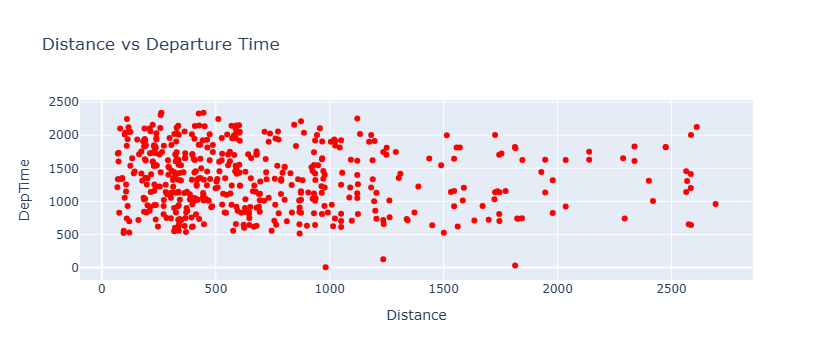

In [26]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=data['Distance'], y=data['DepTime'], mode='markers', marker=dict(color='red')))
fig.update_layout(title='Distance vs Departure Time', xaxis_title='Distance', yaxis_title='DepTime')
fig.show()

Double-click **here** for hint.
<!-- 
***Use go.scatter() method*** and mode as markers
-->


Double-click **here** for the solution.

<!-- The answer is below:

    
##First we will create an empty figure ising go.Figure()
fig=go.Figure()
#Next we will create a scatter plot by using the add_trace function and use the go.scatter() function within it
# In go.Scatter we define the x-axis data,y-axis data and define the mode as markers with color of the marker as red
fig.add_trace(go.Scatter(x=data['Distance'], y=data['DepTime'], mode='markers', marker=dict(color='red')))
fig.update_layout(title='Distance vs Departure Time', xaxis_title='Distance', yaxis_title='DepTime')
# Display the figure
fig.show()
-->


#### Inferences

It can be inferred that there are more flights round the clock for shorter distances. However, for longer distance there are limited flights through the day.


## 2. Line Plot


Let us now use a line plot to extract average monthly arrival delay time and see how it changes over the year.

  This plot should contain the following

* Title as **Month vs Average Flight Delay Time**.
* x-axis label should be **Month**
* y-axis label should be **ArrDelay**
* A new dataframe **line_data** should be created which consists of 2 columns average **arrival delay time per month** and **month** from the dataset
* **Month** column data from the line_data dataframe should be considered in x-axis
* **ArrDelay** column data from the ine_data dataframeshould be considered in y-axis
* Plotted line in the line plot should be of green color


In [27]:
# Group the data by Month and compute average over arrival delay time.
line_data = data.groupby('Month')['ArrDelay'].mean().reset_index()

In [28]:
# Display the data
line_data

,Month,ArrDelay
0,1,2.232558
1,2,2.687500
2,3,10.868421
3,4,6.229167
4,5,-0.279070
5,6,17.310345
6,7,5.088889
7,8,3.121951
8,9,9.081081
9,10,1.200000


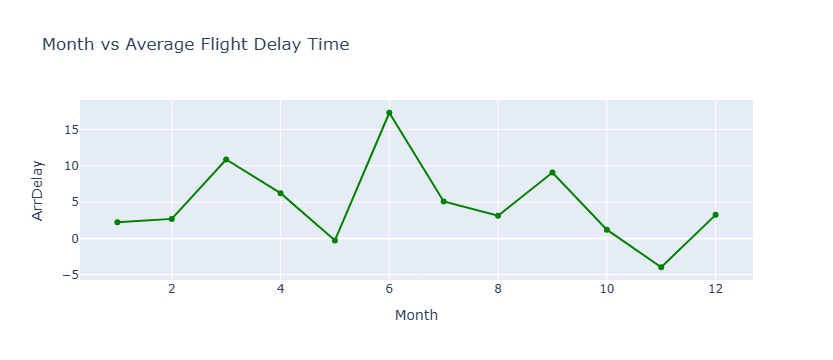

In [29]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=line_data['Month'], y=line_data['ArrDelay'], mode='lines+markers', line=dict(color='green')))
fig.update_layout(title='Month vs Average Flight Delay Time', xaxis_title='Month', yaxis_title='ArrDelay')
fig.show()

Double-click **here** for hint.
<!--
*   Hint: Scatter and line plot vary by updating mode parameter.
-->


Double-click **here** for the solution.

<!-- The answer is below:

    
##First we will create an empty figure ising go.Figure()
fig=go.Figure()
##Next we will create a line plot by using the add_trace function and use the go.scatter() function within it
# In go.Scatter we define the x-axis data,y-axis data and define the mode as lines with color of the marker as green
fig.add_trace(go.Scatter(x=line_data['Month'], y=line_data['ArrDelay'], mode='lines', marker=dict(color='green')))
# Create line plot here
## Here we update these values under function attributes such as title,xaxis_title and yaxis_title
fig.update_layout(title='Month vs Average Flight Delay Time', xaxis_title='Month', yaxis_title='ArrDelay')
fig.show()
-->


#### Inferences

It is found that in the month of June the average monthly delay time is the maximum


## 3. Bar Chart



Let us use a bar chart to extract number of flights that goes to a destination

This plot should contain the following

* Title as **Total number of flights to the destination state split by reporting air**.
* x-axis label should be **DestState**
* y-axis label should be **Flights**
* Create a new dataframe called **bar_data**  which contains 2 columns **DestState** and **Flights**.Here **flights** indicate total number of flights in each combination.



In [30]:
# Follow the task wording: split destination totals by reporting airline.
bar_data = data.groupby(['DestState', 'Reporting_Airline'])['Flights'].sum().reset_index()

In [31]:
# Display the data
bar_data

,DestState,Reporting_Airline,Flights
0,AK,AS,3.0
1,AK,DL,1.0
2,AL,AA,1.0
3,AL,EV,1.0
4,AL,XE,1.0
...,...,...,...
201,WI,MQ,1.0
202,WI,NW,1.0
203,WI,OO,2.0
204,WI,WN,1.0


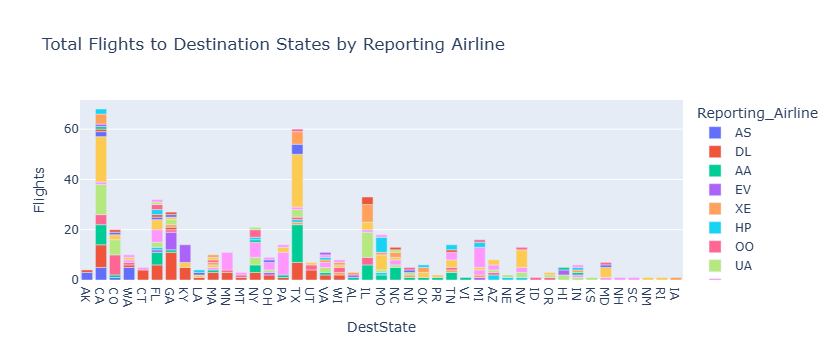

In [32]:
fig = px.bar(bar_data, x='DestState', y='Flights', color='Reporting_Airline',
             title='Total Flights to Destination States by Reporting Airline')
fig.show()

Double-click **here** for hint.
<!--
***Use the px.bar() function***
-->


Double-click **here** for the solution.

<!-- The answer is below:

    
# Use plotly express bar chart function px.bar. Provide input data, x and y axis variable, and title of the chart.
# This will give total number of flights to the destination state.
fig = px.bar(bar_data, x="DestState", y="Flights", title='Total number of flights to the destination state split by reporting airline') 
fig.show()
-->


#### Interpretation

In the fixed 500-record sample, CA has 68 flights. VT has no record in this sample; several other states have one. The colored segments identify reporting airlines.

## 4. Histogram



Let us represent the distribution of arrival delay using a histogram

This plot should contain the following

* Title as **Total number of flights to the destination state split by reporting air**.
* x-axis label should be **ArrayDelay**
* y-axis will show the count of arrival delay


In [33]:
# Do not invent zero delay for an unreported arrival delay.
missing_arrival_delay = int(data['ArrDelay'].isna().sum())
print('Missing arrival-delay observations excluded from histogram:', missing_arrival_delay)

Missing arrival-delay observations excluded from histogram: 15


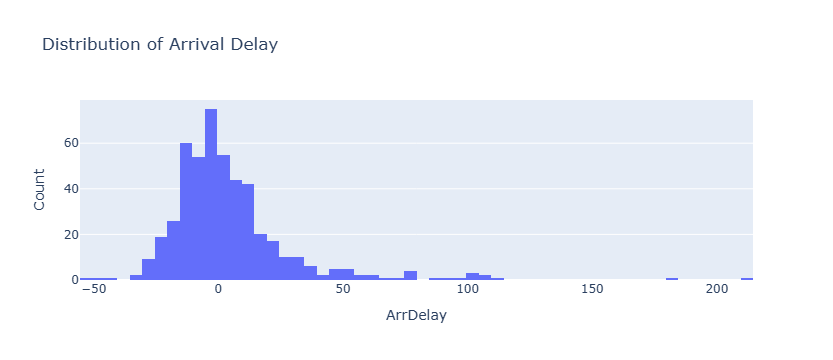

In [34]:
fig = px.histogram(data.dropna(subset=['ArrDelay']), x='ArrDelay', title='Distribution of Arrival Delay')
fig.update_layout(xaxis_title='ArrDelay', yaxis_title='Count')
fig.show()

Double-click **here** for hint.
<!--
***Use the px.histogram() function***
-->


Double-click **here** for the solution.

<!-- The answer is below:
## Use plotly express histogram chart function px.histogram.Provide input data x to the histogram
fig = px.histogram(data, x="ArrDelay",title="Total number of flights to the destination state split by reporting air.")
fig.show()
    

-->


#### Interpretation

The histogram counts observed arrival-delay values; negative values mean early arrival. Missing values are excluded and their count is printed above. Bin counts depend on the displayed bin boundaries.

## 5. Bubble Plot


Let  use a bubble plot to represent number of flights as per reporting airline

This plot should contain the following

* Title as **Reporting Airline vs Number of Flights**.
* x-axis label should be **Reporting_Airline**
* y-axis label should be **Flights**
* size of the bubble should be **Flights** indicating number of flights
* Name of the hover tooltip to `reporting_airline` using `hover_name` parameter.


In [35]:
# Group the data by reporting airline and get number of flights
bub_data = data.groupby('Reporting_Airline')['Flights'].sum().reset_index()

In [36]:
bub_data

,Reporting_Airline,Flights
0,9E,5.0
1,AA,57.0
2,AS,14.0
3,B6,10.0
4,CO,12.0
5,DL,66.0
6,EA,4.0
7,EV,11.0
8,F9,4.0
9,FL,3.0


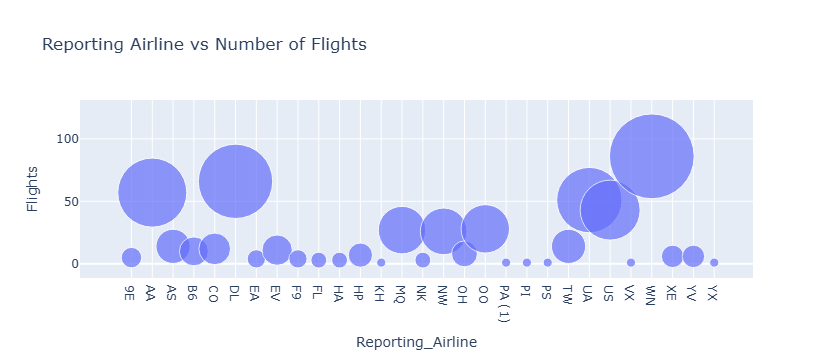

In [37]:
fig = px.scatter(bub_data, x='Reporting_Airline', y='Flights', size='Flights',
                 hover_name='Reporting_Airline', title='Reporting Airline vs Number of Flights', size_max=60)
fig.show()

Double-click **here** for hint.
<!--
***Use the px.scatter() function and define the size attribute values apart from x and y attribute values***
-->


Double-click **here** for the solution.

<!-- The answer is below:
## Bubble chart using px.scatter function with x ,y and size variables defined.Title defined as Reporting Airline vs Number of Flights
fig = px.scatter(bub_data, x="Reporting_Airline", y="Flights", size="Flights",
                 hover_name="Reporting_Airline", title='Reporting Airline vs Number of Flights', size_max=60)
fig.show()
    

-->


#### Inferences

It is found that the reporting airline **WN** has the highest number of flights which is around 86


## 6. Pie Chart


Let us represent the proportion of distance group by month (month indicated by numbers)

This plot should contain the following

* Title as **Distance group proportion by month**.
* values should be **Month**
* names should be **DistanceGroup**


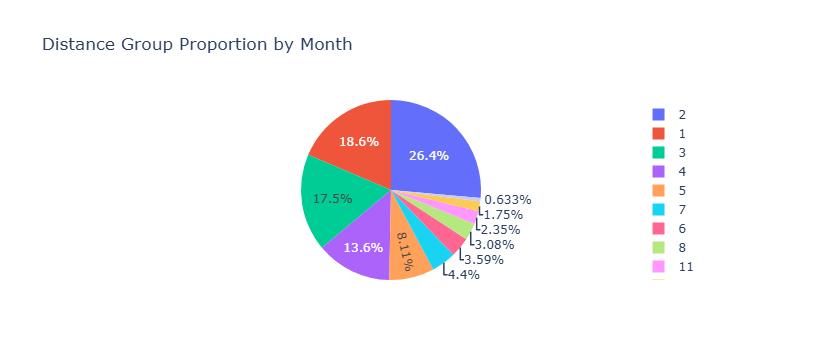

In [38]:
fig = px.pie(data, values='Month', names='DistanceGroup', title='Distance Group Proportion by Month')
fig.show()

Double-click **here** for hint.
<!--
***Use the px.pie() function***
-->


Double-click **here** for the solution.

<!-- The answer is below:
# Use px.pie function to create the chart. Input dataset. 
# Values parameter will set values associated to the sector. 'Month' feature is passed to it.
# labels for the sector are passed to the `names` parameter.
fig = px.pie(data, values='Month', names='DistanceGroup', title='Distance group proportion by month')
fig.show()
    

-->


#### Interpretation

This teacher-specified exercise sums the numeric Month values within each DistanceGroup. The slices therefore encode a month-number-weighted total, not flight proportions for February or any other month. A valid count-based distance-group pie is shown in Exercise I.

## 7. SunBurst Charts


Let us represent the hierarchical view in othe order of month and destination state holding value of number of flights

This plot should contain the following

*  Define hierarchy of sectors from root to leaves in `path` parameter. Here, we go from `Month` to `DestStateName` feature.
*   Set sector values in `values` parameter. Here, we can pass in `Flights` feature.
*   Show the figure.
*   Title as **Flight Distribution Hierarchy**


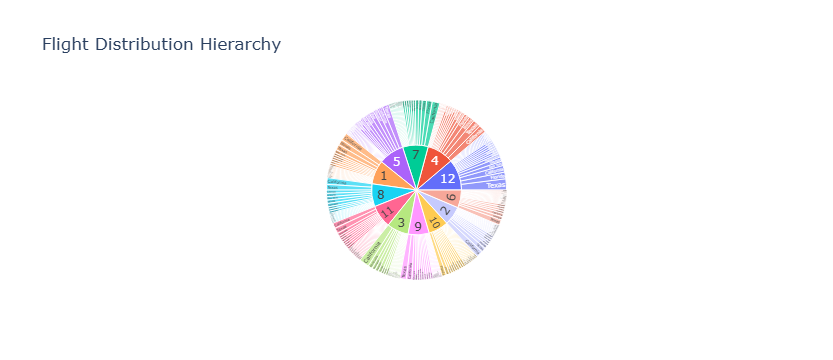

In [39]:
fig = px.sunburst(data, path=['Month', 'DestStateName'], values='Flights', title='Flight Distribution Hierarchy')
fig.show()

Double-click **here** for hint.
<!--
***Use the px.sunburst() function***
-->


Double-click **here** for the solution.

<!-- The answer is below:
## Define path as Month and DestStateName and values as Flights.
fig = px.sunburst(data, path=['Month', 'DestStateName'], values='Flights',title='Flight Distribution Hierarchy')
fig.show()
    

-->


#### Inferences

Here the  **Month** numbers present in the innermost concentric circle is the root and for each month we will check the **number of flights** for the different **destination states** under it.


## Summary

Congratulations for completing your lab.

In this lab, you have learnt how to use `plotly.graph_objects` and `plotly.express` for creating plots and charts.


## Author(s)
[Saishruthi Swaminathan](https://www.linkedin.com/in/saishruthi-swaminathan/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork970-2022-01-01)

Lakshmi Holla


## Other Contributor(s)

Lavanya T S


## <h3 align="center"> © IBM Corporation 2023. All rights reserved. <h3/>
```{toggle}## Changelog
```
```{toggle}| Date       | Version | Changed by | Change Description                   |
```
```{toggle}| ---------- | ------- | ---------- | ------------------------------------ |
```
```{toggle}| 07-02-2023 | 1.1     | Lakshmi Holla     | Updated lab |
```


## Generative AI Use Disclosure

OpenAI Codex assisted with code review, corrections, execution checks, screenshot capture, and documentation. The notebooks were executed locally during assisted verification. The submitting student remains responsible for reviewing the code, outputs, and interpretations and explaining the submitted work.